# Homework 01: Matrix Multiplication Performance Comparison

Họ tên: Nguyễn lê Hoàng Trung

MSSV: 23122004


## 2.1. Giới thiệu

Bài tập này nhằm mục đích so sánh hiệu năng của phép nhân ma trận trên ba phương pháp triển khai khác nhau:

1.  **Pure C:** Sử dụng ngôn ngữ biên dịch bậc thấp với cấp phát bộ nhớ thủ công và ba vòng lặp lồng nhau. Đây được coi là baseline về hiệu năng.
2.  **Pure Python:** Sử dụng ngôn ngữ thông dịch bậc cao với cấu trúc dữ liệu danh sách (list) và các vòng lặp `for` gốc.
3.  **NumPy:** Một thư viện Python được tối ưu hóa cao cho tính toán số, sử dụng các phép toán được vector hóa.

**Phương pháp đo lường:**
Để đảm bảo kết quả chính xác, mỗi phép thử chọn một kích thước ma trận cụ thể và chạy 5 lần. Thời gian thực thi cuối cùng là giá trị trung bình của các lần chạy.

**Khởi tạo ma trận:**
Tất cả các ma trận trong bài tập này đều là ma trận vuông ($N \times N$) và được khởi tạo ngẫu nhiên với các giá trị số thực trong khoảng $[0, 1]$.

**Các kích thước ma trận sẽ sử dụng:**
Các kích thước ma trận vuông sẽ được sử dụng để đánh giá: $64 \times 64$, $128 \times 128$, $256 \times 256$, $512 \times 512$, và $1024 \times 1024$.

**Lưu ý:** Phép thử với Pure Python cho kích thước lớn hơn $256 \times 256$ sẽ bị bỏ qua do thời gian thực thi quá dài.

## 2.3. Mã cài đặt

### Thiết lập môi trường

In [1]:
import os
import subprocess
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Cấu hình cho biểu đồ
plt.style.use('seaborn-v0_8-whitegrid')

### Mã nguồn C

Để biên dịch và thực thi mã C từ Python, chúng ta sẽ sử dụng thư viện `subprocess`:

1. Biên dịch file C (matrix_mult.c) bằng lệnh gcc.
2. Chạy chương trình C đã biên dịch (./matrix_mult).
3. Đọc kết quả đầu ra (stdout) để lấy thời gian thực thi.

In [2]:
compile_cmd = ["gcc", "-O3", "matrix_mult.c", "-o", "matrix_mult"]
try:
    subprocess.run(compile_cmd, check=True, capture_output=True, text=True)
    print("Biên dịch mã C thành công: `matrix_mult.exe` đã được tạo.")
except subprocess.CalledProcessError as e:
    print("Lỗi biên dịch C:")
    print(e.stderr)

Biên dịch mã C thành công: `matrix_mult.exe` đã được tạo.


### Mã nguồn Python

In [3]:
def multiply_matrices_python(A, B):
    """Nhân ma trận bằng Pure Python."""
    n = len(A)
    C = [[0 for _ in range(n)] for _ in range(n)] # Khởi tạo ma trận 0

    for i in range(n):
        for j in range(n):
            for k in range(n):
                C[i][j] += A[i][k] * B[k][j]
    return C

def multiply_matrices_numpy(A, B):
    """Nhân ma trận bằng NumPy."""
    return A @ B

### Xử lý chính

In [4]:
matrix_sizes = [64, 128, 256, 512, 1024]
num_trials = 5
results = []

for n in matrix_sizes:
    # Kiểm tra kích thước ma trận, bỏ qua nếu kích thước lớn hơn 256x256 cho Pure Python

    # --- Pure Python ---
    if n > 256:
        python_avg_time = float('nan')
    else:
        python_times = []
        for _ in range(num_trials):
            A = [[random.random() for _ in range(n)] for _ in range(n)]
            B = [[random.random() for _ in range(n)] for _ in range(n)]
            start_time = time.time()
            multiply_matrices_python(A, B)
            end_time = time.time()
            python_times.append((end_time - start_time) * 1000) # milliseconds
        python_avg_time = sum(python_times) / len(python_times)

    # --- NumPy ---
    numpy_times = []
    for _ in range(num_trials):
        A = np.random.rand(n, n)
        B = np.random.rand(n, n)
        start_time = time.time()
        multiply_matrices_numpy(A, B)
        end_time = time.time()
        numpy_times.append((end_time - start_time) * 1000) # milliseconds
    numpy_avg_time = sum(numpy_times) / len(numpy_times)

    # --- C ---
    c_times = []
    executable = "matrix_mult.exe"
    if os.path.exists(executable):
        for _ in range(num_trials):
            result = subprocess.run([executable, str(n)], capture_output=True, text=True)
            c_times.append(float(result.stdout))
        c_avg_time = sum(c_times) / len(c_times)
    else:
        c_avg_time = float('nan')

    results.append({
        "Size": n,
        "Pure Python": python_avg_time,
        "NumPy": numpy_avg_time,
        "C": c_avg_time
    })

df_results = pd.DataFrame(results).set_index("Size")

## 2.4. Kết quả và Trực quan hóa

### Bảng dữ liệu thời gian thực thi

In [5]:
df_results.style.format("{:.2f}").set_caption("Thời gian thực thi trung bình (ms)")

,Pure Python,NumPy,C
Size,,,
64,25.00,3.00,0.20
128,204.79,0.20,1.20
256,1646.24,0.59,15.40
512,nan,1.60,129.00
1024,nan,12.21,1505.40


### Biểu đồ trực quan hóa

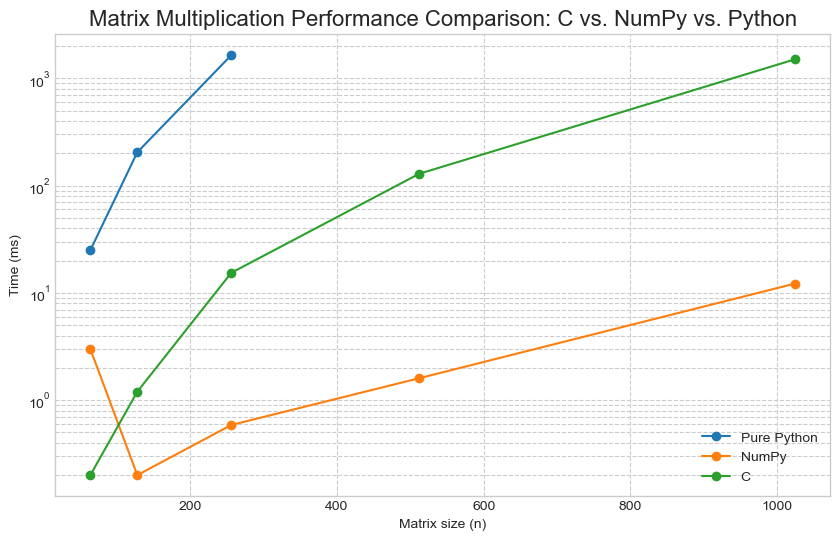

In [6]:
fig, ax = plt.subplots(figsize=(10, 6))

df_results.plot(ax=ax, marker='o')

ax.set_title('Matrix Multiplication Performance Comparison: C vs. NumPy vs. Python', fontsize=16)
ax.set_xlabel('Matrix size (n)')
ax.set_ylabel('Time (ms)')
ax.set_yscale('log')
ax.grid(True, which="both", ls="--")

plt.show()

### Phân tích tăng tốc

Để hiểu rõ hơn về mức độ chênh lệch hiệu suất, chúng ta sẽ tính toán "hệ số tăng tốc" (speedup) của C và NumPy so với Pure Python.

-   **Speedup = Thời gian thực thi (chậm) / Thời gian thực thi (nhanh)**

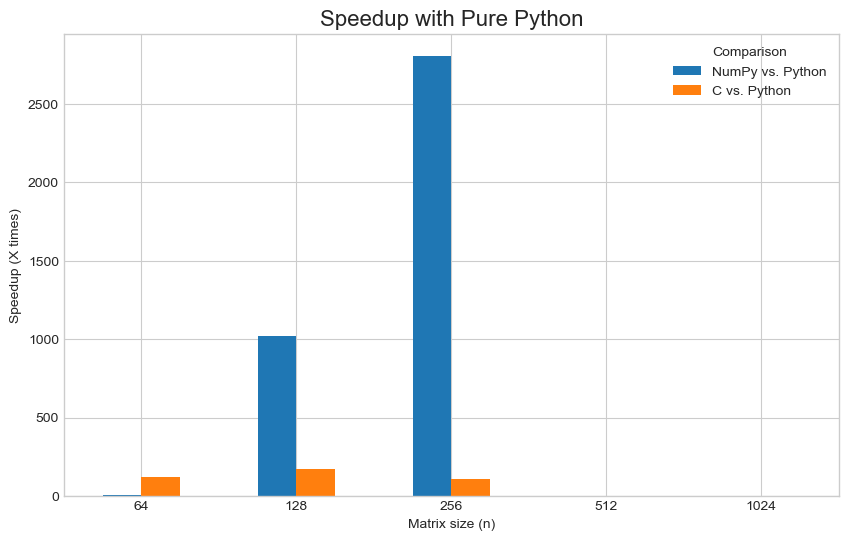


Bảng dữ liệu hệ số tăng tốc:


,NumPy vs. Python,C vs. Python,NumPy vs. C
Size,,,
64,8.33x,125.02x,0.07x
128,1023.04x,170.66x,5.99x
256,2803.65x,106.90x,26.23x
512,nanx,nanx,80.52x
1024,nanx,nanx,123.26x


In [7]:
df_speedup = pd.DataFrame(index=df_results.index)
df_speedup['NumPy vs. Python'] = df_results['Pure Python'] / df_results['NumPy']
df_speedup['C vs. Python'] = df_results['Pure Python'] / df_results['C']
df_speedup['NumPy vs. C'] = df_results['C'] / df_results['NumPy']

fig, ax = plt.subplots(figsize=(10, 6))

df_speedup[['NumPy vs. Python', 'C vs. Python']].plot(kind='bar', ax=ax)

ax.set_title('Speedup with Pure Python', fontsize=16)
ax.set_xlabel('Matrix size (n)')
ax.set_ylabel('Speedup (X times)')
ax.legend(title='Comparison')
plt.xticks(rotation=0)

plt.show()

print("\nBảng dữ liệu hệ số tăng tốc:")
display(df_speedup.style.format("{:.2f}x"))

## 2.5. Phân tích và Thảo luận

Dựa trên dữ liệu thu thập được, chúng ta có thể rút ra các kết luận sau:

**1. Xếp hạng hiệu suất: Nhanh nhất? Chậm nhất? Mức độ chênh lệch?**
-   **Nhanh nhất:** **Numpy** là phương pháp nhanh nhất.
-   **Chậm nhất:** **Pure Python** là phương pháp chậm nhất.
-   **Ở giữa:** **C** nhanh hơn đáng kể so với Pure Python nhưng vẫn chậm hơn đáng kể so với NumPy.
-   **Mức độ chênh lệch**: Khoảng cách hiệu suất rất lớn. Tại kích thước $256 \times 256$, C nhanh hơn Python khoảng **~106 lần**, , và NumPy nhanh hơn C khoảng **~26** lần. Khoảng cách này càng lớn khi kích thước ma trận tăng lên.

**2. Hành vi co giãn (Scaling): Thời gian thực thi tăng theo kích thước ma trận như thế nào? Nó có khớp với kỳ vọng O(n³)**
Độ phức tạp lý thuyết của thuật toán nhân ma trận ba vòng lặp là **O(n³)**, nghĩa là khi kích thước *n* tăng gấp đôi, **thời gian thực thi tăng gấp \(2^3 = 8\) lần**.

- **Pure Python và C:**
  Dữ liệu cho thấy cả hai đều tuân theo quy luật O(n³) khá ổn định. Ví dụ: thời gian C tăng từ **15.40 ms (256×256)** lên **129.00 ms (512×512)** → tăng ~8.3 lần.

- **NumPy:**
  Hành vi co giãn phức tạp hơn. Ở kích thước nhỏ, thời gian không tăng theo đúng tỉ lệ 8×, nhưng khi tăng từ **512 → 1024**, thời gian từ **1.60 ms → 12.21 ms** (~7.6×), gần với O(n³). Điều này cho thấy NumPy đã sử dụng những **thuật toán tối ưu cao** — khiến hành vi co giãn khác biệt ở các kích thước khác nhau.

**3. Python vs C: Tại sao Pure Python chậm hơn C rất nhiều?**
Sự khác biệt về tốc độ giữa C và Python xuất phát từ bản chất của hai ngôn ngữ:
-   **Biên dịch vs. Thông dịch:** C là ngôn ngữ biên dịch, mã nguồn được dịch trực tiếp sang mã máy tối ưu cho phần cứng trước khi thực thi. Python là ngôn ngữ thông dịch, trình thông dịch đọc và thực thi mã từng dòng một, tạo ra một lượng lớn chi phí hoạt động, đặc biệt là trong các vòng lặp.
-   **Kiểu dữ liệu động vs. tĩnh:** Python sử dụng kiểu dữ liệu động, do đó trình thông dịch phải thực hiện các kiểm tra kiểu dữ liệu trong thời gian chạy, làm chậm quá trình thực thi. C sử dụng kiểu tĩnh, kiểu dữ liệu được xác định tại thời điểm biên dịch, cho phép các phép toán số học được thực hiện trực tiếp ở cấp độ phần cứng, tối ưu hóa việc truy cập bộ nhớ.
-   **Quản lý bộ nhớ:** Trong C, mỗi hàng ma trận được cấp phát một khối bộ nhớ liền kề, phù hợp với cách lưu trữ của bộ nhớ cache. Trong Python, danh sách (list) là các mảng con trỏ đến các đối tượng, các đối tượng này có thể nằm rải rác trong bộ nhớ, không đảm bảo tính liên tục về bộ nhớ, dẫn đến nhiều lỗi cache (cache misses) hơn và làm truy cập bộ nhớ chậm hơn.

**4. Hiệu suất của NumPy:**
-   **Tại sao NumPy nhanh hơn nhiều so với Pure Python?**
    NumPy không thực hiện các phép toán, vòng lặp trong Python. Thay vào đó, nó gọi các hàm được viết bằng C và Fortran đã được biên dịch và tối ưu hóa cao. Khi bạn gọi `A @ B`, NumPy chuyển toàn bộ phép toán ma trận xuống các thư viện được biên dịch, tối ưu hóa cao như **BLAS** (Basic Linear Algebra Subprograms) và **LAPACK**. Các vòng lặp tính toán diễn ra ở tốc độ của mã máy, loại bỏ hoàn toàn chi phí của trình thông dịch Python cho các phép toán tính toán. Hơn nữa, các mảng NumPy sử dụng các khối bộ nhớ liền kề, giống như trong C, cho phép truy cập dữ liệu hiệu quả.

-   **NumPy so với C như thế nào? Tại sao?**
    NumPy nhanh hơn đáng kể so với triển khai C đơn giản. Các thư viện mà NumPy sử dụng BLAS (Basic Linear Algebra Subprograms) và LAPACK (Linear Algebra Package) (như OpenBLAS, MKL) còn được tối ưu hóa hơn nữa, bao gồm:
    -   **Vectorization (SIMD):** Sử dụng các tập lệnh đặc biệt của CPU (như SSE, AVX) để thực hiện cùng một phép toán trên nhiều phần tử dữ liệu cùng một lúc.
    -   **Cache Efficiency:** Sử dụng các thuật toán "blocking" để chia ma trận thành các khối nhỏ hơn vừa với bộ nhớ cache của CPU, giảm thiểu thời gian truy cập bộ nhớ chính.
    -   **Đa luồng (Multithreading):** Các thư viện này thường tự động song song hóa các phép tính trên nhiều lõi CPU.

**5. Kết quả bất ngờ:**
Một thư viện của Python (Numpy) lại vượt trội hiệu suất hơn một chương trình C được biên dịch với -O3. Điều này nhấn mạnh rằng: ngôn ngữ lập trình không phải là yếu tố duy nhất quyết định hiệu suất.

## 2.6 Kết luận

Bài tập này đã chứng minh rõ ràng sự khác biệt về hiệu năng giữa các môi trường lập trình khác nhau cho các tác vụ tính toán số học.
-   **Pure Python** mặc dù rất dễ sử dụng, linh hoạt nhưng lại quá chậm cho các tác vụ tính toán số lặp đi lặp lại do bản chất thông dịch và kiểu dữ liệu động của nó.
-   **C** cung cấp hiệu năng thô tốt nhất do tiếp cận gần với phần cứng.
-   **NumPy** là giải pháp tối ưu trong hệ sinh thái Python, kết hợp tính dễ sử dụng của Python với hiệu suất cực cao của các thư viện C/Fortran được tối ưu hóa cao như BLAS và LAPACK.

**Tổng kết:** Đối với tính toán số học trong Python (đặc biệt trong các lĩnh vực liên quan đến học máy), việc sử dụng các thư viện như NumPy không chỉ là một sự tiện lợi, mà còn là điều thiết yếu để đạt được hiệu suất chấp nhận được.